# Assignment 3 – Predicting Chemotherapy Resistance from DNA Methylation Data

Group: Hatice AY, Bedia Nur ELMAS, Mahyar Naeimi

The task is to predict whether a cell is chemotherapy sensitive (0) or resistant (1) from the methylation level (beta value between 0 and 1) of 50 CpG sites. Step 1 loads, merges and inspects the data. Step 2 runs a stratified 5-fold cross-validation for two models without data leakage. Step 3 compares the ROC-AUC of the two models and tests the difference. Step 4 compares three techniques for the class imbalance. The two CSV files (methylation.csv and chemoresistance_labels.csv) are given with the assignment. In Google Colab they have to be uploaded when the notebook asks for them.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
pd.set_option("display.width", 120)

## Step 1 – Load and inspect the dataset

In [2]:
METH_PATH = "methylation.csv"
LABEL_PATH = "chemoresistance_labels.csv"

# In Google Colab: upload the two CSV files if they are not in the working directory yet.
if not (Path(METH_PATH).exists() and Path(LABEL_PATH).exists()):
    from google.colab import files
    files.upload()

# The first column of both files holds the cell ID but has no name ("Unnamed: 0").
meth = pd.read_csv(METH_PATH).rename(columns={"Unnamed: 0": "Cell_ID"})
labels = pd.read_csv(LABEL_PATH).rename(
    columns={"Unnamed: 0": "Cell_ID", "Chemotherapy_Resistance": "resistant"}
)

print("methylation:", meth.shape, "| labels:", labels.shape)
print("Cell IDs unique -> methylation:", meth["Cell_ID"].is_unique, "| labels:", labels["Cell_ID"].is_unique)
only_meth = set(meth["Cell_ID"]) - set(labels["Cell_ID"])
only_lab = set(labels["Cell_ID"]) - set(meth["Cell_ID"])
print("IDs only in methylation:", len(only_meth), "| IDs only in labels:", len(only_lab))

methylation: (1000, 51) | labels: (1000, 2)
Cell IDs unique -> methylation: True | labels: True
IDs only in methylation: 0 | IDs only in labels: 0


In [3]:
# Merge on the Cell ID column. validate="one_to_one" raises an error if an ID were duplicated.
df = meth.merge(labels, on="Cell_ID", how="inner", validate="one_to_one")
cpg_cols = [c for c in df.columns if c.startswith("CpG_")]
print("Merged table:", df.shape, "->", len(cpg_cols), "CpG features + label")

print("\nMissing labels:", int(df["resistant"].isna().sum()))
print("Label values  :", sorted(df["resistant"].unique().tolist()))

Merged table: (1000, 52) -> 50 CpG features + label

Missing labels: 0
Label values  : [0, 1]


### Missing values and impossible values

Beta values are proportions, so valid values lie in [0, 1]. We check this first, because a placeholder code such as -9999 would otherwise be treated as a real measurement.

In [4]:
vals = df[cpg_cols]
print(f"Missing (NaN) cells: {int(vals.isna().sum().sum())} ({vals.isna().mean().mean():.1%} of all cells)")
print("Values < 0:", int((vals < 0).sum().sum()), "| values > 1:", int((vals > 1).sum().sum()))
print("\nImpossible values:")
neg = vals.stack()
print(neg[neg < 0])

# Any value outside [0, 1] is physically impossible -> treat as missing.
df[cpg_cols] = vals.where((vals >= 0) & (vals <= 1))
print("\nMissing cells after recoding:", int(df[cpg_cols].isna().sum().sum()))

Missing (NaN) cells: 4203 (8.4% of all cells)
Values < 0: 1 | values > 1: 0

Impossible values:
384  CpG_26   -9999.0
dtype: float64

Missing cells after recoding: 4204


,fraction missing
CpG_14,0.990
CpG_25,0.990
CpG_33,0.990
CpG_46,0.036
CpG_13,0.035
CpG_27,0.033
CpG_42,0.032
CpG_5,0.031


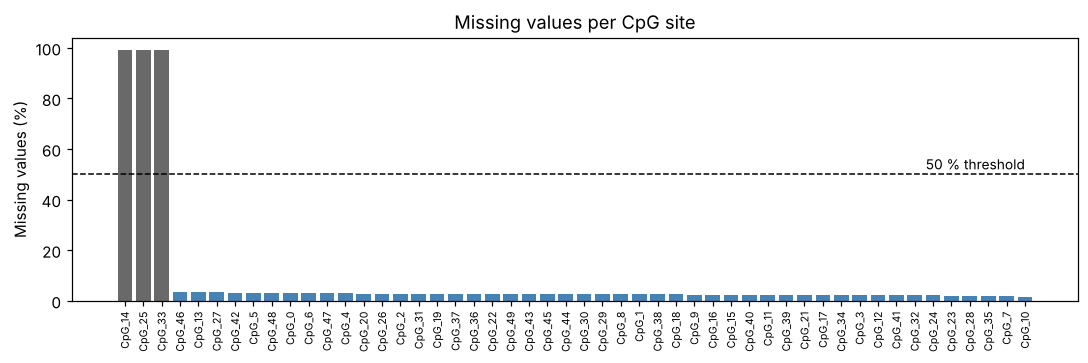

In [5]:
miss = df[cpg_cols].isna().mean().sort_values(ascending=False)
display(miss.head(8).to_frame("fraction missing").round(3))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(miss)), miss.values * 100, color=np.where(miss.values > 0.5, "dimgray", "steelblue"))
ax.axhline(50, color="k", ls="--", lw=1)
ax.text(len(miss) - 1, 52, "50 % threshold", ha="right", fontsize=9)
ax.set_xticks(range(len(miss)))
ax.set_xticklabels(miss.index, rotation=90, fontsize=7)
ax.set_ylabel("Missing values (%)")
ax.set_title("Missing values per CpG site")
plt.tight_layout()
plt.show()

### Findings

Out of 50 CpG sites, three (`CpG_14`, `CpG_25`, `CpG_33`) are missing in 99 % of the cells, so only about 10 of 1000 values were actually measured. Imputing them would mean inventing 99 % of the column, so these three sites are **dropped**. All other sites have at most 3.6 % missing values. They are **kept** and imputed later. In addition, one beta value of -9999 (cell 384, `CpG_26`) is clearly a placeholder code and was converted to a missing value above.

In [6]:
MAX_MISSING = 0.5          # drop CpG sites with more than 50 % missing values
drop_cols = miss[miss > MAX_MISSING].index.tolist()
feature_cols = [c for c in cpg_cols if c not in drop_cols]

print("Dropped CpG sites:", drop_cols)
print("Remaining features:", len(feature_cols))
print(f"Largest missing fraction among the remaining sites: {miss.drop(drop_cols).max():.1%}")
print("Remaining missing cells:", int(df[feature_cols].isna().sum().sum()),
      f"({df[feature_cols].isna().mean().mean():.1%})")

# Missing values per CELL (row): how are they distributed?
miss_per_cell = df[feature_cols].isna().sum(axis=1)
print("\nNumber of missing features per cell -> number of cells:")
print(miss_per_cell.value_counts().sort_index().to_dict())

Dropped CpG sites: ['CpG_14', 'CpG_25', 'CpG_33']
Remaining features: 47
Largest missing fraction among the remaining sites: 3.6%
Remaining missing cells: 1234 (2.6%)

Number of missing features per cell -> number of cells:
{0: 386, 1: 365, 2: 178, 3: 54, 4: 9, 5: 1, 44: 5, 45: 2}


Almost all cells have 0-5 missing values, but a small group of cells has **44-45 of the 47 features missing**, i.e. these cells are essentially empty measurements. Imputing them would just replace them with the median profile of all other cells, which carries no information about the cell and would inject artificial data points. Cells with more than 50 % missing features are therefore removed. This decision uses only the feature matrix, never the label.

In [7]:
MAX_MISSING_ROW = 0.5
empty = df[feature_cols].isna().mean(axis=1) > MAX_MISSING_ROW
print("Removed cells:", df.loc[empty, "Cell_ID"].tolist())
print("Their labels :", df.loc[empty, "resistant"].tolist())
df = df.loc[~empty].reset_index(drop=True)
print("Cells remaining:", len(df))

print("Remaining missing cells:", int(df[feature_cols].isna().sum().sum()),
      f"({df[feature_cols].isna().mean().mean():.1%}) -> handled by median imputation inside the CV pipeline")

# Is the remaining missingness related to the label?
row_missing = df[feature_cols].isna().sum(axis=1)
print("\nMissing features per cell, by class:")
print(row_missing.groupby(df["resistant"]).agg(["mean", "max"]).round(2))
u = stats.mannwhitneyu(row_missing[df.resistant == 0], row_missing[df.resistant == 1])
print(f"Mann-Whitney U test, missing count vs. label: p = {u.pvalue:.3f}")

Removed cells: ['Cell_66', 'Cell_170', 'Cell_295', 'Cell_409', 'Cell_462', 'Cell_507', 'Cell_581']
Their labels : [0, 0, 0, 0, 0, 0, 0]
Cells remaining: 993
Remaining missing cells: 924 (2.0%) -> handled by median imputation inside the CV pipeline

Missing features per cell, by class:
           mean  max
resistant           
0          0.91    5
1          1.03    4
Mann-Whitney U test, missing count vs. label: p = 0.100


### Target distribution

Sensitive (0): 843  (84.9%)
Resistant (1): 150  (15.1%)
Imbalance ratio: 5.62 : 1
Accuracy of always predicting 'sensitive': 0.849


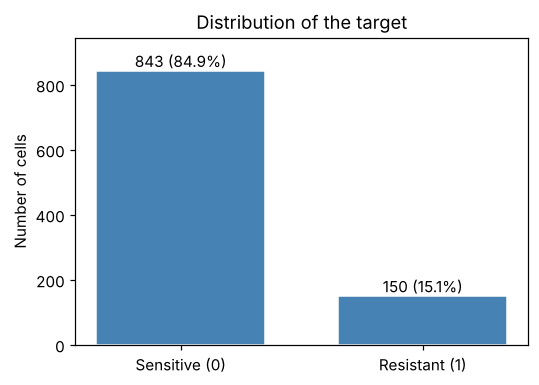

In [8]:
y = df["resistant"].astype(int).to_numpy()
counts = np.bincount(y)
print(f"Sensitive (0): {counts[0]}  ({counts[0] / len(y):.1%})")
print(f"Resistant (1): {counts[1]}  ({counts[1] / len(y):.1%})")
print(f"Imbalance ratio: {counts[0] / counts[1]:.2f} : 1")
print(f"Accuracy of always predicting 'sensitive': {counts[0] / len(y):.3f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.hist(y, bins=[-0.5, 0.5, 1.5], rwidth=0.7, color="steelblue", edgecolor="white")
for x_, c_ in zip([0, 1], counts):
    ax.text(x_, c_ + 12, f"{c_} ({c_ / len(y):.1%})", ha="center")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Sensitive (0)", "Resistant (1)"])
ax.set_ylabel("Number of cells")
ax.set_ylim(0, counts.max() * 1.12)
ax.set_title("Distribution of the target")
plt.tight_layout()
plt.show()

### Findings

- The two files contain the same 1000 Cell IDs, so the merge loses nothing. No label is missing.
- Features: 3 CpG sites with 99 % missing values were dropped, and 7 nearly empty cells (44-45 of 47 features missing, all labelled sensitive) were removed. This leaves **993 cells x 47 CpG sites**.
- About 2 % of the remaining feature values are missing. The number of missing values per cell does not differ clearly between the two classes (Mann-Whitney p = 0.10), so there is no evidence that missingness carries label information. The remaining values are filled by **median imputation**. The median is robust to outliers and does not change the distribution much.
- The target is **imbalanced**: 843 sensitive (84.9 %) vs. 150 resistant (15.1 %), a ratio of about 5.6 : 1. A model that always predicts "sensitive" would already reach 84.9 % accuracy, so accuracy is not a useful metric here. We use **ROC-AUC**, which does not depend on a threshold and is not dominated by the majority class.

## Step 2 – Five-fold cross-validation

In [9]:
X = df[feature_cols]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y))          # the SAME folds are used for every model and every experiment

rows = []
for i, (tr, te) in enumerate(folds, 1):
    rows.append({"fold": i, "n_train": len(tr), "n_test": len(te),
                 "resistant in train": int(y[tr].sum()), "resistant in test": int(y[te].sum())})
display(pd.DataFrame(rows).set_index("fold"))

,n_train,n_test,resistant in train,resistant in test
fold,,,,
1,794,199,120,30
2,794,199,120,30
3,794,199,120,30
4,795,198,120,30
5,795,198,120,30


In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

def make_pipeline(model):
    # Imputer and scaler live INSIDE the pipeline -> they are fitted on the training part of each fold only.
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", clone(model)),
    ])

fold_proba = {name: [] for name in models}      # predicted P(resistant) on each test fold
for name, model in models.items():
    for tr, te in folds:
        pipe = make_pipeline(model).fit(X.iloc[tr], y[tr])
        fold_proba[name].append(pipe.predict_proba(X.iloc[te])[:, 1])
print("Cross-validation finished for:", list(models))

# Sanity check: scikit-learn's own cross_val_score (which also refits the whole pipeline per fold) must agree.
for name, model in models.items():
    ref = cross_val_score(make_pipeline(model), X, y, cv=folds, scoring="roc_auc")
    mine = [roc_auc_score(y[te], p) for (tr, te), p in zip(folds, fold_proba[name])]
    print(f"{name:20s} identical to cross_val_score: {np.allclose(ref, mine)}")

Cross-validation finished for: ['Logistic Regression', 'Random Forest']
Logistic Regression  identical to cross_val_score: True
Random Forest        identical to cross_val_score: True


### Decisions

- **Stratified** 5-fold CV with shuffling keeps the 15 % share of resistant cells in every fold (30 resistant cells per test fold). The same folds are used for both models and for all experiments in Step 4, so the AUCs can be compared **pairwise**.
- **No data leakage:** the median imputer and the standard scaler are part of a `Pipeline` and are fitted on the training part of each fold only. The test fold is merely transformed with the training statistics. (Dropping the 3 empty CpG sites and the 7 empty cells was based only on the amount of missing data, never on the labels.) The check above confirms that the manual loop gives exactly the same AUCs as scikit-learn's `cross_val_score`.
- **Models:** *Logistic Regression* (linear, L2-regularised, interpretable, a strong baseline for about 800 training cells and 47 features) and *Random Forest* (non-linear, can model interactions between CpG sites, robust to noisy features). They have different inductive biases, which makes the comparison informative. Standardisation matters for logistic regression and is harmless for the forest. Hyperparameters were left at sensible defaults and not tuned.

## Step 3 – Evaluation and testing

In [11]:
fold_names = [f"Fold {i}" for i in range(1, 6)]
auc = pd.DataFrame(
    {name: [roc_auc_score(y[te], p) for (tr, te), p in zip(folds, fold_proba[name])] for name in models},
    index=fold_names,
)
summary = pd.DataFrame({"mean AUC": auc.mean(), "std": auc.std(ddof=1)})
display(auc.round(4))
display(summary.round(4))

# Accuracy at the default 0.5 threshold, to show why accuracy is misleading here
acc = {name: np.mean([((p >= 0.5).astype(int) == y[te]).mean() for (tr, te), p in zip(folds, fold_proba[name])])
       for name in models}
print("Mean accuracy at threshold 0.5:", {k: round(float(v), 3) for k, v in acc.items()})
print(f"Majority-class baseline accuracy: {1 - y.mean():.3f}")

,Logistic Regression,Random Forest
Fold 1,0.9047,0.8280
Fold 2,0.8373,0.7328
Fold 3,0.8864,0.7293
Fold 4,0.8903,0.8062
Fold 5,0.8752,0.7244


,mean AUC,std
Logistic Regression,0.8788,0.0255
Random Forest,0.7641,0.0490


Mean accuracy at threshold 0.5: {'Logistic Regression': 0.865, 'Random Forest': 0.849}
Majority-class baseline accuracy: 0.849


In [12]:
def corrected_paired_ttest(diff, n_train, n_test):
    # Nadeau & Bengio (2003): the k fold scores share training data, so they are not independent.
    # The naive paired t-test underestimates the variance; the correction inflates it by (1/k + n_test/n_train).
    k = len(diff)
    var = np.var(diff, ddof=1)
    t = np.mean(diff) / np.sqrt((1 / k + n_test / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), df=k - 1)

a, b = auc["Logistic Regression"].to_numpy(), auc["Random Forest"].to_numpy()
diff = a - b
n_test, n_train = np.mean([len(te) for _, te in folds]), np.mean([len(tr) for tr, _ in folds])

t_naive = stats.ttest_rel(a, b)
w = stats.wilcoxon(a, b)
t_corr, p_corr = corrected_paired_ttest(diff, n_train, n_test)

print("Mean AUC difference (Logistic Regression - Random Forest): %.4f" % diff.mean())
print("Fold-wise differences:", np.round(diff, 4))
print(f"Paired t-test (naive)            : t = {t_naive.statistic:6.3f}, p = {t_naive.pvalue:.4f}")
print(f"Wilcoxon signed-rank (n = 5)     : W = {w.statistic:6.1f}, p = {w.pvalue:.4f}  (smallest possible p with 5 folds = 0.0625)")
print(f"Corrected resampled t-test (N&B) : t = {t_corr:6.3f}, p = {p_corr:.4f}")

Mean AUC difference (Logistic Regression - Random Forest): 0.1146
Fold-wise differences: [0.0767 0.1044 0.1571 0.0841 0.1508]
Paired t-test (naive)            : t =  6.862, p = 0.0024
Wilcoxon signed-rank (n = 5)     : W =    0.0, p = 0.0625  (smallest possible p with 5 folds = 0.0625)
Corrected resampled t-test (N&B) : t =  4.574, p = 0.0102


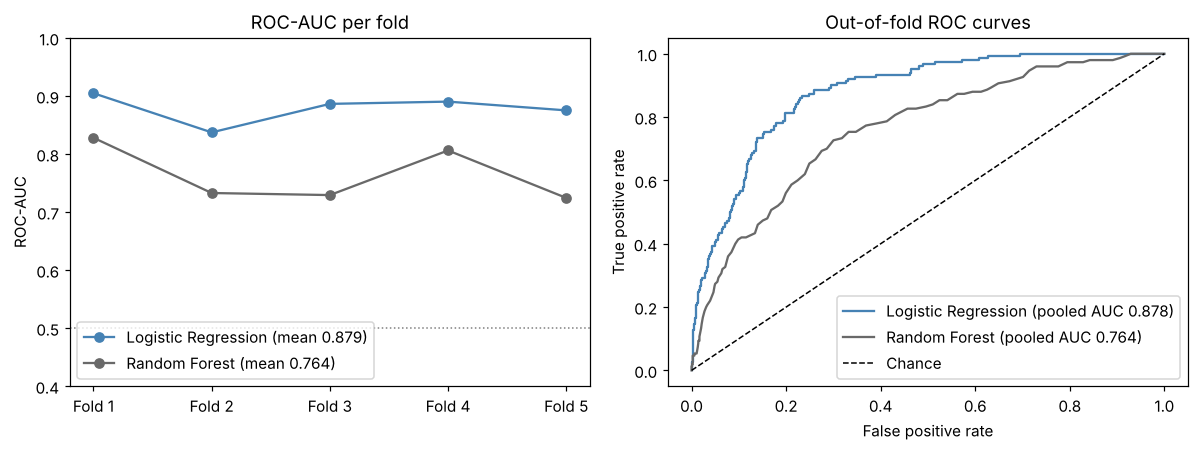

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
for name, color in zip(models, ["steelblue", "dimgray"]):
    ax.plot(fold_names, auc[name], "o-", label=f"{name} (mean {auc[name].mean():.3f})", color=color)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold")
ax.legend(loc="lower left")

ax = axes[1]
for name, color in zip(models, ["steelblue", "dimgray"]):
    # out-of-fold predictions of all five test folds pooled together
    y_all = np.concatenate([y[te] for _, te in folds])
    p_all = np.concatenate(fold_proba[name])
    fpr, tpr, _ = roc_curve(y_all, p_all)
    ax.plot(fpr, tpr, label=f"{name} (pooled AUC {roc_auc_score(y_all, p_all):.3f})", color=color)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Out-of-fold ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Findings

- Both models rank resistant cells above sensitive ones better than chance (AUC 0.5), so the methylation data does contain signal. **Logistic Regression** reaches a mean AUC of **0.879 ± 0.026** and **Random Forest** only **0.764 ± 0.049**. Logistic Regression is better in all five folds (by 0.08-0.16 AUC).
- The accuracy numbers show why AUC is the right metric: at threshold 0.5 the Random Forest (0.849) is exactly as accurate as always predicting "sensitive" (0.849), and Logistic Regression (0.865) is barely better, although its AUC is clearly high.
- **Significance.** The naive paired t-test gives p = 0.002, but it is too optimistic because the five folds share training data and are not independent. The corrected resampled t-test (Nadeau & Bengio) gives **t = 4.57, p = 0.010**, so the difference is significant at the 5 % level. The Wilcoxon test can never get below p = 0.0625 with only 5 folds, so it cannot reach significance here by construction. It agrees in direction (LR better in 5/5 folds) but has no power.
- So Logistic Regression significantly outperforms the untuned Random Forest on this data. A plausible explanation (not tested here) is that the signal is mostly additive and roughly linear across several CpG sites. A forest with about 120 resistant training cells can use such a signal less efficiently, and it is also affected by the class imbalance. This conclusion holds for the tested settings and does not prove that a tuned forest could never catch up.

## Step 4 – Handling class imbalance

Three techniques are compared with the unbalanced baseline: **class weights**, **random oversampling** and **SMOTE**. All resampling is done on the training part of each fold only, after imputation and scaling. The test folds are never resampled.

In [14]:
def random_oversample(X_, y_, rng):
    # Duplicate randomly chosen minority samples until both classes have the same size.
    idx_min = np.flatnonzero(y_ == 1)
    n_new = int((y_ == 0).sum() - (y_ == 1).sum())
    pick = rng.choice(idx_min, size=n_new, replace=True)
    return np.vstack([X_, X_[pick]]), np.concatenate([y_, y_[pick]])

def smote(X_, y_, rng, k=5):
    # SMOTE (Chawla et al. 2002): create synthetic minority samples on the line between a minority
    # sample and one of its k nearest minority neighbours.
    X_min = X_[y_ == 1]
    n_new = int((y_ == 0).sum() - (y_ == 1).sum())
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_min))).fit(X_min)
    neigh = nn.kneighbors(X_min, return_distance=False)[:, 1:]          # drop the point itself
    base = rng.integers(0, len(X_min), n_new)
    other = neigh[base, rng.integers(0, neigh.shape[1], n_new)]
    gap = rng.random((n_new, 1))
    X_new = X_min[base] + gap * (X_min[other] - X_min[base])
    return np.vstack([X_, X_new]), np.concatenate([y_, np.ones(n_new, dtype=int)])

techniques = {
    "None (baseline)":      {"sampler": None,              "class_weight": None},
    "Class weights":        {"sampler": None,              "class_weight": "balanced"},
    "Random oversampling":  {"sampler": random_oversample, "class_weight": None},
    "SMOTE":                {"sampler": smote,             "class_weight": None},
}

def cv_auc(model, sampler=None, class_weight=None):
    scores = []
    for i, (tr, te) in enumerate(folds):
        imputer = SimpleImputer(strategy="median").fit(X.iloc[tr])          # fitted on training data only
        scaler = StandardScaler().fit(imputer.transform(X.iloc[tr]))
        Xtr = scaler.transform(imputer.transform(X.iloc[tr]))
        Xte = scaler.transform(imputer.transform(X.iloc[te]))
        ytr = y[tr]
        if sampler is not None:
            Xtr, ytr = sampler(Xtr, ytr, np.random.default_rng(SEED + i))  # training part only
        clf = clone(model)
        if class_weight is not None:
            clf.set_params(class_weight=class_weight)
        clf.fit(Xtr, ytr)
        scores.append(roc_auc_score(y[te], clf.predict_proba(Xte)[:, 1]))
    return np.array(scores)

results = {(m, t): cv_auc(model, **cfg) for m, model in models.items() for t, cfg in techniques.items()}

# Sanity check: the baseline must reproduce the Step 3 numbers exactly.
for m in models:
    print(f"Baseline of {m} equals Step 3:", np.allclose(results[(m, "None (baseline)")], auc[m]))

Baseline of Logistic Regression equals Step 3: True
Baseline of Random Forest equals Step 3: True


In [15]:
table = pd.DataFrame(
    {m: {t: f"{results[(m, t)].mean():.4f} ± {results[(m, t)].std(ddof=1):.4f}" for t in techniques} for m in models}
)
display(table)

rows = []
for m in models:
    base = results[(m, "None (baseline)")]
    for t in list(techniques)[1:]:
        d = results[(m, t)] - base
        _, p = corrected_paired_ttest(d, n_train, n_test)
        rows.append({"model": m, "technique": t, "mean AUC": results[(m, t)].mean(),
                     "change vs. baseline": d.mean(), "folds improved": f"{int((d > 0).sum())}/5",
                     "p (corrected t-test)": p})
display(pd.DataFrame(rows).round(4).set_index(["model", "technique"]))

,Logistic Regression,Random Forest
None (baseline),0.8788 ± 0.0255,0.7641 ± 0.0490
Class weights,0.8833 ± 0.0208,0.8218 ± 0.0273
Random oversampling,0.8810 ± 0.0158,0.8214 ± 0.0400
SMOTE,0.8783 ± 0.0225,0.8012 ± 0.0266


mean AUC  change vs. baseline folds improved  p (corrected t-test)
model               technique                                                                              
Logistic Regression Class weights          0.8833               0.0045            4/5                0.2653
                    Random oversampling    0.8810               0.0023            2/5                0.7743
                    SMOTE                  0.8783              -0.0005            3/5                0.9387
Random Forest       Class weights          0.8218               0.0577            5/5                0.0207
                    Random oversampling    0.8214               0.0572            5/5                0.0296
                    SMOTE                  0.8012               0.0371            4/5                0.2340

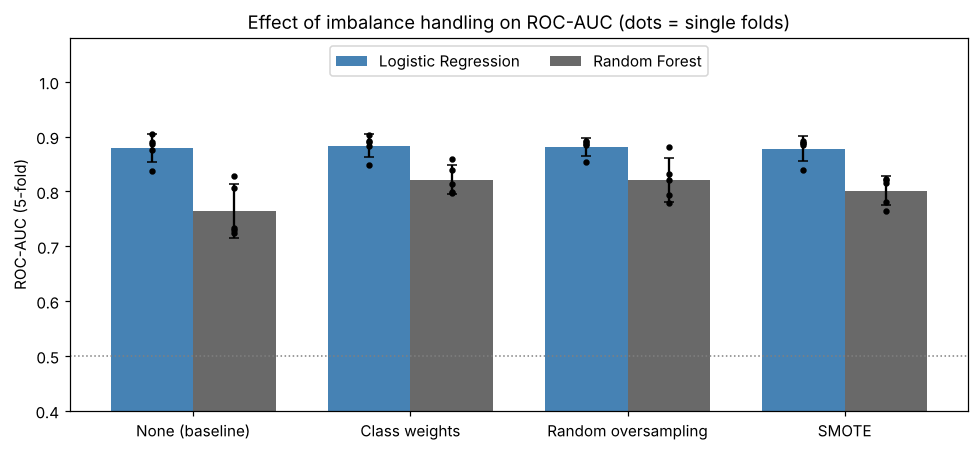

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.38
x_pos = np.arange(len(techniques))
for j, (m, color) in enumerate(zip(models, ["steelblue", "dimgray"])):
    means = [results[(m, t)].mean() for t in techniques]
    stds = [results[(m, t)].std(ddof=1) for t in techniques]
    ax.bar(x_pos + (j - 0.5) * width, means, width, yerr=stds, capsize=3, label=m, color=color)
    for xi, t in zip(x_pos, techniques):
        ax.scatter(np.full(5, xi + (j - 0.5) * width), results[(m, t)], s=10, color="k", zorder=3)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xticks(x_pos)
ax.set_xticklabels(list(techniques))
ax.set_ylim(0.4, 1.08)
ax.set_ylabel("ROC-AUC (5-fold)")
ax.set_title("Effect of imbalance handling on ROC-AUC (dots = single folds)")
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

### Findings

- **Logistic Regression** gains almost nothing from any technique: the changes are between -0.001 and +0.005 AUC and none is significant (corrected p between 0.27 and 0.94). This is expected. AUC only depends on how the cells are *ranked*, and re-weighting the classes mostly shifts the decision threshold and changes the ranking only slightly.
- **Random Forest** profits clearly. Class weights (+0.058 AUC, better in 5/5 folds, p = 0.021) and random oversampling (+0.057, 5/5 folds, p = 0.030) both help. SMOTE helps less (+0.037, 4/5 folds, p = 0.23, not significant). A likely reason is that with only 120 minority cells in 47 dimensions, interpolated SMOTE points are less realistic than simply re-using real cells or re-weighting them (this is a hypothesis, not tested here).
- Even with the best technique the Random Forest (about 0.82) stays below Logistic Regression (about 0.88). Imbalance handling reduces the gap but does not remove it.

**Caveats.** (1) Six comparisons to the baseline were made, and after a Bonferroni correction (alpha = 0.05 / 6 = 0.008) none of them would be significant, so the Random Forest improvements should be read as *consistent evidence*, not as proven. (2) Five folds with about 30 resistant test cells each give noisy AUCs (standard deviation 0.02-0.05). Repeated cross-validation would give more stable estimates. (3) Models were not tuned.

**Recommendation.** Use Logistic Regression with class weights (best mean AUC 0.883, simple and interpretable). If a Random Forest is used, combine it with class weights or random oversampling.

## References

Data

[1] methylation.csv and chemoresistance_labels.csv, provided with Assignment 3 of the course (no further source was given).

Methods

[2] Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. Journal of Artificial Intelligence Research, 16, 321–357.

[3] Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. Machine Learning, 52(3), 239–281.

[4] Wilcoxon, F. (1945). Individual comparisons by ranking methods. Biometrics Bulletin, 1(6), 80–83.

[5] Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. Annals of Mathematical Statistics, 18(1), 50–60.

Software

[6] Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.

[7] Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261–272.

[8] Harris, C. R. et al. (2020). Array programming with NumPy. Nature, 585, 357–362.

[9] McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56–61.

[10] Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95.

Course material

[11] Introduction to Focus Areas, Data Science part, WS 2026/27: Assignment 3 sheet.